# BankAssist Phase 3 - EDA notebook (Suraj)

Dataset: BANKING77 training file (`data/raw/train.csv`) and the shared splits made by Anuja
(`data/processed/train.csv`, `validation.csv`). The official test set is **not** used anywhere here.

Sections: 1 overview, 2 quality checks, 3 class distribution, 4 query lengths, 5 sample inspection,
6 vocabulary and confusable intents, 7 what this means for preprocessing and models.

Run from the repository root or from `notebooks/`. Figures are saved to `results/eda/`.

In [1]:
import json, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw" / "train.csv"
TRAIN = ROOT / "data" / "processed" / "train.csv"
VALID = ROOT / "data" / "processed" / "validation.csv"
MAPPING = ROOT / "data" / "processed" / "label_mapping.json"
FIG = ROOT / "results" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv(RAW, keep_default_na=False)
train = pd.read_csv(TRAIN, keep_default_na=False)
valid = pd.read_csv(VALID, keep_default_na=False)
mapping = json.loads(MAPPING.read_text(encoding="utf-8"))
print("SHA-256 of raw file:", hashlib.sha256(RAW.read_bytes()).hexdigest())

SHA-256 of raw file: c13c6d140f3072e184179261fe8204a9094b9fa3b021bcc4ddb3174ee36eea83


## 1. Dataset overview

In [2]:
overview = pd.DataFrame({
    "file": ["raw train.csv", "processed train.csv", "processed validation.csv"],
    "rows": [len(raw), len(train), len(valid)],
    "columns": [", ".join(raw.columns), ", ".join(train.columns), ", ".join(valid.columns)],
    "intents": [raw.category.nunique(), train.category.nunique(), valid.category.nunique()],
})
display(overview)
print("Intents in label_mapping.json:", len(mapping))
raw.head()

,file,rows,columns,intents
0,raw train.csv,10003,"text, category",77
1,processed train.csv,7999,"record_id, text, category, text_clean",77
2,processed validation.csv,2000,"record_id, text, category, text_clean",77


Intents in label_mapping.json: 77


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


## 2. Quality checks

In [3]:
norm = lambda s: " ".join(s.split())
raw["norm"] = raw.text.map(norm)
checks = {
    "Missing / empty text": int((raw.text.str.strip() == "").sum()),
    "Missing / empty category": int((raw.category.str.strip() == "").sum()),
    "Exact duplicate texts": int(raw.text.duplicated(keep=False).sum()),
    "Duplicate after whitespace normalisation (rows in repeated groups)": int(raw.norm.duplicated(keep=False).sum()),
    "Normalised questions with more than one label": int((raw.groupby("norm").category.nunique() > 1).sum()),
    "Leading/trailing whitespace": int((raw.text != raw.text.str.strip()).sum()),
    "Runs of 2+ whitespace characters": int(raw.text.str.contains(r"\s{2,}").sum()),
    "Non-ASCII characters": int((~raw.text.map(str.isascii)).sum()),
    "Starts with a lowercase letter": int(raw.text.str.strip().str[0].str.islower().sum()),
    "No final . ? or !": int((~raw.text.str.strip().str[-1].isin(list(".?!"))).sum()),
    "Single-word queries": int((raw.text.str.split().str.len() == 1).sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
Missing / empty text,0
Missing / empty category,0
Exact duplicate texts,0
Duplicate after whitespace normalisation (rows in repeated groups),8
Normalised questions with more than one label,0
Leading/trailing whitespace,9
Runs of 2+ whitespace characters,456
Non-ASCII characters,52
Starts with a lowercase letter,525
No final . ? or !,1319


In [4]:
dups = raw[raw.norm.duplicated(keep=False)].sort_values("norm")[["text", "category"]]
dups

,text,category
6910,Do I need to go to a physical bank to change m...,change_pin
6965,\nDo I need to go to a physical bank to change...,change_pin
1246,I can't seem to be able to use my card,card_not_working
1290,\nI can't seem to be able to use my card\n\n\n,card_not_working
1710,\nI put the wrong pin too many times and now i...,pin_blocked
1724,I put the wrong pin too many times and now it ...,pin_blocked
4594,Where can I withdraw money from?,atm_support
4595,\nWhere can I withdraw money from?,atm_support


In [5]:
na = raw[~raw.text.map(str.isascii)].text.head(8)
for t in na: print(repr(t))

'Why do I see an extra £1 charge on my statement?'
"There is a pending 1£ charge on my statement.  I haven't purchased anything for 1£.  Why is it on my statement?"
'I have a strange transaction for £1 on my statement, what is that?'
'Where did this extra €1 fee on my statement come from?'
'Is there a reason why there is an extra £1 charge on my account?'
'€1 was in my statement as an extra fee.'
'There is a €1 extra fee in my statement'
'What is the extra €1 on my statement for?'


## 3. Class distribution

count     77.0
mean     129.9
std       32.9
min       35.0
25%      112.0
50%      127.0
75%      159.0
max      187.0

Largest / smallest class ratio: 5.34


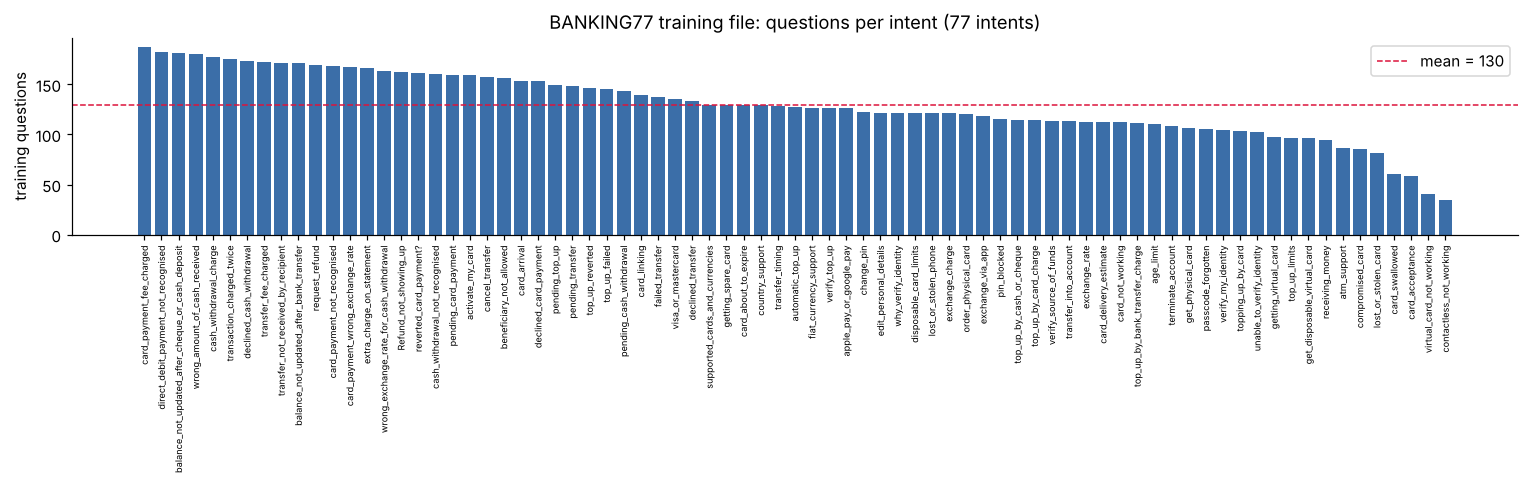

In [6]:
counts = raw.category.value_counts()
print(counts.describe().round(1).to_string())
print("\nLargest / smallest class ratio: {:.2f}".format(counts.max() / counts.min()))
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(range(len(counts)), counts.values, color="#3b6ea8")
ax.axhline(counts.mean(), color="crimson", ls="--", lw=1, label="mean = {:.0f}".format(counts.mean()))
ax.set_xticks(range(len(counts))); ax.set_xticklabels(counts.index, rotation=90, fontsize=6)
ax.set_ylabel("training questions"); ax.set_title("BANKING77 training file: questions per intent (77 intents)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "class_distribution.png"); plt.show()

In [7]:
pd.concat([counts.head(5).rename("count").to_frame().assign(group="largest"),
           counts.tail(5).rename("count").to_frame().assign(group="smallest")])

,count,group
category,,
card_payment_fee_charged,187,largest
direct_debit_payment_not_recognised,182,largest
balance_not_updated_after_cheque_or_cash_deposit,181,largest
wrong_amount_of_cash_received,180,largest
cash_withdrawal_charge,177,largest
lost_or_stolen_card,82,smallest
card_swallowed,61,smallest
card_acceptance,59,smallest
virtual_card_not_working,41,smallest


Train rows: 7999  Validation rows: 2000
Largest gap in an intent's share between train and validation: 0.0373%


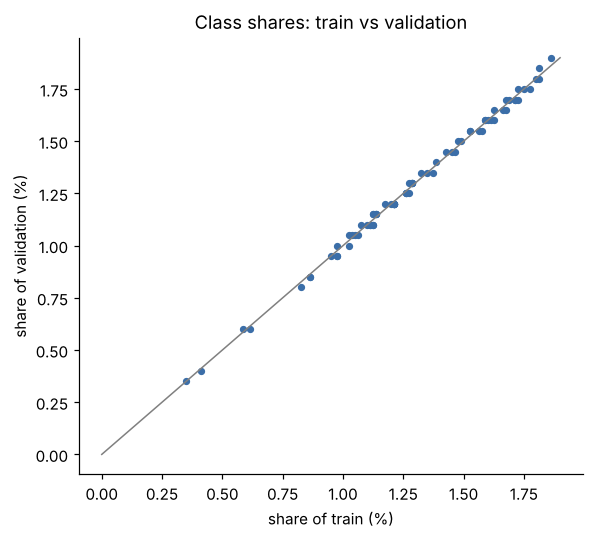

Smallest class in train: contactless_not_working (28 rows); in validation: contactless_not_working (7 rows)


In [8]:
tr_share = train.category.value_counts(normalize=True)
va_share = valid.category.value_counts(normalize=True)
gap = (tr_share - va_share).abs()
print("Train rows: {}  Validation rows: {}".format(len(train), len(valid)))
print("Largest gap in an intent's share between train and validation: {:.4%}".format(gap.max()))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(tr_share * 100, va_share.reindex(tr_share.index) * 100, s=14, color="#3b6ea8")
m = max(tr_share.max(), va_share.max()) * 100
ax.plot([0, m], [0, m], color="grey", lw=1)
ax.set_xlabel("share of train (%)"); ax.set_ylabel("share of validation (%)")
ax.set_title("Class shares: train vs validation"); fig.tight_layout()
fig.savefig(FIG / "split_class_shares.png"); plt.show()
print("Smallest class in train: {} ({} rows); in validation: {} ({} rows)".format(
    train.category.value_counts().idxmin(), train.category.value_counts().min(),
    valid.category.value_counts().idxmin(), valid.category.value_counts().min()))

## 4. Query lengths

      characters  words
0.50        47.0   10.0
0.90       109.8   22.0
0.95       151.9   29.0
0.99       221.0   43.0
1.00       433.0   79.0

mean words 11.9, std 7.9


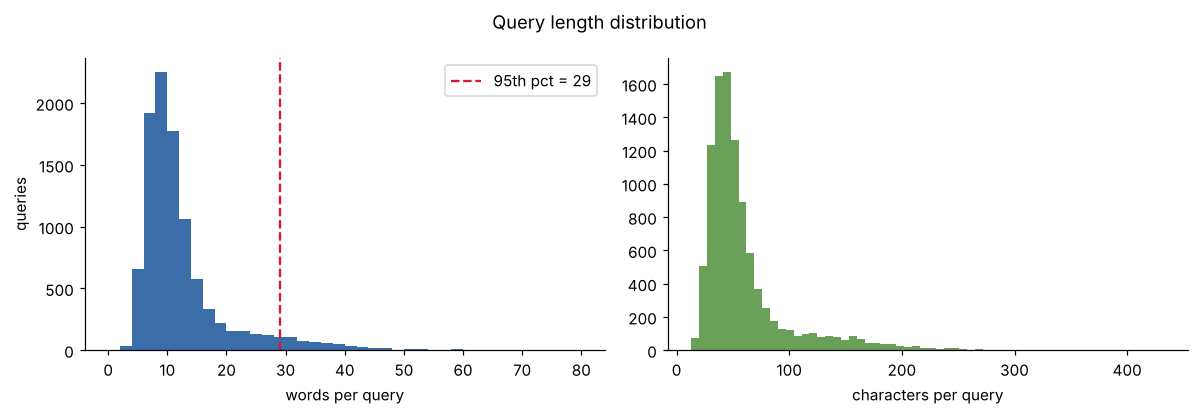

In [9]:
raw["chars"] = raw.text.str.len()
raw["words"] = raw.text.str.split().str.len()
pcts = [0.5, 0.9, 0.95, 0.99, 1.0]
print(pd.DataFrame({"characters": raw.chars.quantile(pcts), "words": raw.words.quantile(pcts)}).round(1).to_string())
print("\nmean words {:.1f}, std {:.1f}".format(raw.words.mean(), raw.words.std()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(raw.words, bins=range(0, 81, 2), color="#3b6ea8"); axes[0].set_xlabel("words per query"); axes[0].set_ylabel("queries")
axes[0].axvline(raw.words.quantile(0.95), color="crimson", ls="--", label="95th pct = {:.0f}".format(raw.words.quantile(0.95))); axes[0].legend()
axes[1].hist(raw.chars, bins=60, color="#6a9f58"); axes[1].set_xlabel("characters per query")
fig.suptitle("Query length distribution"); fig.tight_layout(); fig.savefig(FIG / "query_lengths.png"); plt.show()

In [10]:
for n in (12, 20, 30, 50):
    print("queries longer than {} words: {}".format(n, int((raw.words > n).sum())))
print()
print("Shortest queries:", raw.nsmallest(6, "words").text.tolist())
print()
long_rows = raw.nlargest(3, "words")
for _, r in long_rows.iterrows():
    print("[{}] ({} words) {}...".format(r.category, r.words, r.text[:160]))

queries longer than 12 words: 2763
queries longer than 20 words: 1077
queries longer than 30 words: 436
queries longer than 50 words: 42

Shortest queries: ['Cancel Transaction', 'passcode retrieval', 'Lost password', 'pending transaction?', 'Transfer declined.', 'Supported countries']

[unable_to_verify_identity] (79 words) Hearing back from us regarding your important verification results may take 10 minutes to one hour time.  If verification results do fail, double-check to make ...
[transfer_fee_charged] (78 words) Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-reference my budget for this month that there were extra fees I was n...
[unable_to_verify_identity] (75 words) Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour.  If this verification has in fact, failed, double-c...


In [11]:
by_class = raw.groupby("category").words.mean().sort_values()
print("Shortest average queries:"); print(by_class.head(4).round(1).to_string())
print("\nLongest average queries:"); print(by_class.tail(4).round(1).to_string())

Shortest average queries:
category
card_acceptance       7.5
atm_support           7.7
passcode_forgotten    7.7
get_physical_card     7.7

Longest average queries:
category
failed_transfer                       16.0
pending_cash_withdrawal               16.5
transfer_fee_charged                  17.4
transfer_not_received_by_recipient    17.5


## 5. Sample inspection

In [12]:
rng = np.random.RandomState(42)
sample_intents = rng.choice(sorted(raw.category.unique()), size=6, replace=False)
for intent in sample_intents:
    print("==", intent)
    for t in raw[raw.category == intent].text.sample(3, random_state=42): print("   -", t)

== atm_support
   - Can you tell me the ATMs I can use with my card?
   - I can use this card at which ATMs?
   - Where are the ATMs that accept this card?
== extra_charge_on_statement
   - There's an extra fee on my statement, why is that?
   - Why i'm I being charged an extra pound
   - What was the $1 charge for on my statement?
== card_about_to_expire
   - I will need a new card because mine is almost expired.  How fast do I get a replacement and what is the cost?
   - When will I get a new card when I order it, and how much will it cost.
   - My card's expiring a month from now, should I place an order for the new card?
== Refund_not_showing_up
   - I made a big purchase that I regretted and cancelled, the merchant said that my refund was submitted. Can you confirm to me that all of my money was truly returned to me?
   - I am still waiting to find out the status of my refund. I have made previous attempts to find out what the status is to no avail. Will you please look into this 

## 6. Vocabulary and confusable intents (training split only)

In [13]:
tok = lambda s: re.findall(r"[a-z0-9']+", s.lower())
train_tokens = [t for s in train.text_clean for t in tok(s)]
valid_tokens = [t for s in valid.text_clean for t in tok(s)]
vocab = set(train_tokens)
oov = sum(t not in vocab for t in valid_tokens) / len(valid_tokens)
print("Training vocabulary (lower-cased word types):", len(vocab))
print("Validation tokens not seen in training: {:.2%}".format(oov))
print("Validation word types not seen in training:", len(set(valid_tokens) - vocab))
from collections import Counter
print("\nMost common training words:", Counter(train_tokens).most_common(15))

Training vocabulary (lower-cased word types): 2186
Validation tokens not seen in training: 0.90%
Validation word types not seen in training: 200

Most common training words: [('i', 6689), ('my', 4517), ('to', 3260), ('a', 2856), ('the', 2835), ('card', 2137), ('is', 1922), ('it', 1519), ('do', 1499), ('can', 1470), ('for', 1259), ('how', 1249), ('what', 1104), ('up', 1096), ('account', 1090)]


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
vec = TfidfVectorizer(sublinear_tf=True, stop_words="english")
X = vec.fit_transform(train.text_clean)   # fitted on the training split only
classes = sorted(train.category.unique())
centroids = np.vstack([np.asarray(X[(train.category == c).to_numpy()].mean(axis=0)) for c in classes])
sim = cosine_similarity(centroids); np.fill_diagonal(sim, 0)
pairs = [(sim[i, j], classes[i], classes[j]) for i in range(len(classes)) for j in range(i + 1, len(classes))]
pairs.sort(reverse=True)
pd.DataFrame(pairs[:12], columns=["centroid_similarity", "intent_a", "intent_b"]).round(3)

,centroid_similarity,intent_a,intent_b
0,0.867,verify_my_identity,why_verify_identity
1,0.831,disposable_card_limits,get_disposable_virtual_card
2,0.817,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal
3,0.811,getting_virtual_card,virtual_card_not_working
4,0.770,unable_to_verify_identity,verify_my_identity
5,0.766,get_physical_card,pin_blocked
6,0.708,get_disposable_virtual_card,virtual_card_not_working
7,0.708,unable_to_verify_identity,why_verify_identity
8,0.693,change_pin,get_physical_card
9,0.685,card_payment_fee_charged,transfer_fee_charged


In [15]:
# Which of those pairs does a baseline actually confuse? Uses Anuja's TF-IDF + LogReg predictions (validation only).
# Note: Kashish's provisional baseline (classifier.py) reports a different accuracy; the team should name one reference.
pred_path = ROOT / "results" / "baseline" / "validation_predictions.csv"
if pred_path.exists():
    p = pd.read_csv(pred_path)
    wrong = p[p.true_intent != p.predicted_intent]
    top = wrong.groupby(["true_intent", "predicted_intent"]).size().sort_values(ascending=False).head(10)
    print("Accuracy of results/baseline/validation_predictions.csv (Anuja baseline): {:.2%}".format((p.true_intent == p.predicted_intent).mean()))
    display(top.rename("errors").to_frame())
else:
    print("Baseline predictions not found; skipped.")

Accuracy of results/baseline/validation_predictions.csv (Anuja baseline): 84.30%


,,errors
true_intent,predicted_intent,
get_disposable_virtual_card,disposable_card_limits,7
direct_debit_payment_not_recognised,card_payment_not_recognised,5
why_verify_identity,unable_to_verify_identity,4
transfer_fee_charged,card_payment_fee_charged,4
top_up_failed,pending_top_up,4
top_up_by_bank_transfer_charge,top_up_by_card_charge,4
transfer_not_received_by_recipient,transfer_timing,4
exchange_via_app,exchange_charge,3
pending_transfer,transfer_not_received_by_recipient,3


## 7. What these findings mean

The numbers below come from the cells above (raw file: 10,003 rows, 77 intents).

**Data quality.** No missing or empty texts or labels, and no queries with conflicting labels. Only four
near-duplicate pairs (differing only in whitespace), which Anuja's preprocessing already removed, leaving 9,999 rows.
About 456 queries contain runs of extra whitespace and 9 have leading/trailing spaces. The `text_clean` column fixes
this without touching case or punctuation, which is the right level of cleaning: 525 queries start lowercase and
1,319 lack final punctuation, so lower-casing or stripping punctuation would change little for TF-IDF and is not needed
for the uncased DistilBERT tokenizer either.

**Class balance.** Intents range from 35 to 187 questions (ratio about 5.3 to 1; mean about 130). That is mild imbalance,
not severe. The shared split is stratified: the largest gap in any intent's share between train and validation is under 0.04 percentage points,
so validation is representative. The smallest validation class has only 7 questions, so per-class F1 for rare intents is noisy
and should be read with that in mind.

**Query length.** Median 10 words, 95th percentile 29 words, 99th percentile 43 words. A maximum sequence length of 64 word-pieces
should cover nearly all queries for DistilBERT. This is an estimate from word counts; the training script logs the real truncation
rate from the tokenizer.

**Unusual rows to flag.** A few of the longest rows read like FAQ answer text rather than customer questions (for example, text about
verification results taking 10 minutes to one hour). They are labelled consistently, so they were kept, but they are outliers.

**Vocabulary.** The training split has 2,186 lower-cased word types. Only 0.90% of validation word tokens (200 word types) never appear in
training, so out-of-vocabulary words are a small effect. TF-IDF cannot use those words at all, while DistilBERT's word-piece tokenizer can
split them into known pieces, but with such a low rate this is unlikely to be the main source of any gain. The 52 queries with non-ASCII
characters are mostly the currency symbols £ and €, which are informative for intents about charges and should not be stripped.

**Confusable intents.** The intent pairs with the most similar training vocabulary (table in section 6) are candidates for confusion. Some
appear in the real baseline errors, for example get_disposable_virtual_card predicted as disposable_card_limits (7 validation errors) and
transfer_fee_charged predicted as card_payment_fee_charged. This supports the confidence-threshold and human-review design: some intents
differ only subtly, so low-confidence cases should escalate.

**Open point for the team.** Two baseline results exist in the repository: `results/baseline/validation_predictions.csv` (Anuja, 84.30%
accuracy on validation) and `docs/baseline_results.md` (Kashish's provisional `classifier.py`, 88.25%). They use different TF-IDF settings.
The team should name one as the reference baseline before the DistilBERT comparison is written up.